# E18 - reranker relevance of a report statement to a single brief

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-12<br>
**Pipeline stage**: experiment - registered batch `E18`, notebook A, hypotheses `E18-H87` and `E18-H91`<br>
**Execution model**: session model (executor of workflow `reports/E18-relevance/workflow-measure.js`)

**Purpose** - measure whether the highest reranker score of a report statement over the sentences of one brief ranks the
statements of the brief's target sections above the other statements better than the nearest ground cost (`E18-H87`),
and whether an exact Otsu split of those scores marks match and no match better than the fixed cutoff on the nearest
cost (`E18-H91`). No other brief is involved in either score.

**Terms used below**

- **baseline** - `b_i = min_j c_ij`, the nearest ground cost of report statement `i` over the brief statements `j`, with `c = cost_matrix(E_report, E_brief)`; a lower value means a more relevant statement; as a relevance score it is `-b_i`
- **reranker score** - `r_i = max_j R[j, i]` with `R = reranker.score_grid(brief statements, report statements)`; a higher value means a more relevant statement
- **AUC** - the probability that a random positive statement has a higher relevance score than a random negative statement, ties count one half
- **positive / negative / neutral** - for a brief, the statements of its target sections / all other scored statements / the statements of `Key findings` and `Overview`, which are left out of every metric
- **control** - one of the 7 gold-tier summaries of the ibm article; its positives are the statements of part 1 and its negatives the statements of part 2
- **new briefs** - briefs 13 to 24 (the headline set, every bar is read on them); **seen briefs** - briefs 01 to 12, scored in E17, reported without a bar

Nothing under `src/`, `tests/`, `docs/` or the fixture is edited. Every bar is the registered one and is applied as
written; a number that is reported without a bar is labelled so.

**Cells copied from the template** `notebooks/experiments/E17-kj-relevance-map.ipynb` without a change of logic: the
environment cell, the `DocDistance()` reading with the `section` field of the `flows`, the label construction (leaf and
part, neutral sections, part-level control labels), `auc`, `section_reading`, the bootstrap, `otsu_threshold` and
`balanced_accuracy`. New in this notebook: the reranker grid, the two score definitions, the contrast reading, the
fixed rule `r_i >= 0.5` and the wall time.

## Environment

No GPU is used. The path under test is the shipped OpenVINO INT8 encoder and reranker on CPU, so `CUDA_VISIBLE_DEVICES`
is set empty before any model import. `DOCDISTANCE_HOME` is pinned to the repository root because `nbconvert` runs with
the notebook folder as the working directory, and `docdistance.json` lives at the repository root.

In [1]:
import os
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # no GPU: the shipped OpenVINO INT8 CPU path is the path under test
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["HF_HUB_OFFLINE"] = "1"                 # models resolve from the local cache through docdistance.json
os.environ["CI"] = "true"                          # disables OpenVINO telemetry
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["DOCDISTANCE_HOME"] = "/home/lab/workspace/learning/projects/docdistance"   # docdistance.json lives at the repo root

warnings.filterwarnings("ignore")
print("environment set: CPU only, models offline, DOCDISTANCE_HOME pinned")

environment set: CPU only, models offline, DOCDISTANCE_HOME pinned


## Imports

The shipped `docdistance` core is imported and never edited. `scipy.stats.rankdata` gives the average ranks of the
Mann-Whitney AUC.

In [2]:
# Standard library
import contextlib                      # silence the model-load stderr output
import hashlib                         # sha256 of the fixture files
import io                              # sink for the redirected stderr
import json                            # labels, registration and metrics JSON
import platform                        # python version
import time                            # wall time and the write stamp
from datetime import datetime, timezone
from pathlib import Path               # fixture paths

# Scientific
import numpy as np                     # arrays
import ot                              # POT version line; the solves run inside the shipped functions
from scipy.stats import rankdata       # average ranks for the Mann-Whitney AUC

# Visualisation
import matplotlib.pyplot as plt        # inline figures, object-oriented API

# Console
from rich.console import Console
from rich.markup import escape         # lists and file names are printed literally
from rich.table import Table

# The shipped package under test - imported, never edited
import docdistance
from docdistance.distance import cost_matrix                      # ground cost sqrt(2 - 2cos)
from docdistance.encoders import load_reranker                    # bge-reranker-v2-m3, OpenVINO INT8
from docdistance.pipeline import DIFF_CHANGED_COST, DocDistance   # shipped reader, segmenter, encoder; fixed cutoff

%matplotlib inline
console = Console(width=200, highlight=False)
T_START = time.time()
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__} | python {platform.python_version()}")

docdistance 1.1.32 | POT 0.9.6.post1 | numpy 2.4.6 | python 3.14.8


## Reproducibility

Segmentation, the INT8 encode, the INT8 rerank and the cost matrix take no random input. The seed governs the bootstrap
of the mean difference only (`numpy.random.default_rng(0)`, 10000 resamples).

In [3]:
SEED = 0
print(f"SEED = {SEED}")

SEED = 0


## Configuration

Every path, constant and bar is set in the next cell and used unchanged. The bars are copied from the registered blocks
of `E18-H87` and `E18-H91` and from the batch opening in `docs/experiments/wmd-docdistance-experiments.md`. The cell
prints the configuration as a table and asserts that the sha256 of every fixture file equals the value stored in
`reports/E18-relevance/E18-relevance-registration.json`.

In [4]:
ROOT = Path(os.environ["DOCDISTANCE_HOME"])
FIXTURE = ROOT / "data/processed/relevance-fixture"
REGISTRATION = ROOT / "reports/E18-relevance/E18-relevance-registration.json"
E17_METRICS = ROOT / "reports/E17-relevance-map-metrics.json"
METRICS_FILE = ROOT / "reports/E18-reranker-relevance-metrics.json"
GRIDS_FILE = ROOT / "data/interim/E18/reranker-grids.npz"

BATCH_GATE_AUC = 0.95                  # baseline mean AUC over briefs 13 to 24 at or above this kills E18-H87 at the gate
BAR_GAIN = 0.03                        # E18-H87: mean AUC difference to the baseline
BAR_COUNT = 10                         # E18-H87: briefs (of 12) with a difference above 0
BAR_CONTROL_DROP = 0.01                # E18-H87: control mean AUC may fall by at most this
H91_GATE_BA = 0.65                     # fixed-cutoff mean balanced accuracy at or above this kills E18-H91 at the gate
H91_BAR_BA = 0.70                      # Otsu mean balanced accuracy must reach this
H91_BAR_GAIN = 0.10                    # and exceed the fixed cutoff's by this
RERANK_FIXED = 0.5                     # reported without a bar: match iff r_i >= 0.5
HARNESS_TOL = 1e-9                     # harness check: absolute difference to the E17 baseline AUC
N_BOOT = 10000                         # bootstrap resamples of the mean difference (reported, no bar)
TOP_N_SECTIONS = 2                     # section-reading top rank

LABELS17 = json.loads((FIXTURE / "labels.json").read_text(encoding="utf-8"))
LABELS18 = json.loads((FIXTURE / "e18/labels.json").read_text(encoding="utf-8"))
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
E17 = json.loads(E17_METRICS.read_text(encoding="utf-8"))
NEUTRAL = LABELS17["neutral_sections"]
PARTS = LABELS17["parts"]
assert LABELS18["neutral_sections"] == NEUTRAL and LABELS18["parts"] == PARTS, "the two label files differ in neutral sections or parts"
assert (FIXTURE / "e18" / LABELS18["report"]).resolve() == (FIXTURE / LABELS17["report"]).resolve(), "the two label files name different reports"

SEEN_IDS = sorted(LABELS17["briefs"])                  # briefs 01 to 12
NEW_IDS = sorted(LABELS18["briefs"])                   # briefs 13 to 24
BRIEF_IDS = SEEN_IDS + NEW_IDS
CONTROL_IDS = list(LABELS17["controls"])
assert SEEN_IDS == [f"brief-{i:02d}" for i in range(1, 13)] and NEW_IDS == [f"brief-{i:02d}" for i in range(13, 25)]
assert list(LABELS18["controls"]) == CONTROL_IDS and len(CONTROL_IDS) == 7
for cid in CONTROL_IDS:
    assert (FIXTURE / "e18" / LABELS18["controls"][cid]["file"]).resolve() == (FIXTURE / LABELS17["controls"][cid]["file"]).resolve()
    assert LABELS18["controls"][cid]["positive_part"] == LABELS17["controls"][cid]["positive_part"]

BRIEF_SPEC = {**{b: {**LABELS17["briefs"][b], "path": (FIXTURE / LABELS17["briefs"][b]["file"]).resolve()} for b in SEEN_IDS},
              **{b: {**LABELS18["briefs"][b], "path": (FIXTURE / "e18" / LABELS18["briefs"][b]["file"]).resolve()} for b in NEW_IDS}}

fixture_sha = {rel: hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() for rel in REG["fixture_sha256"]}
assert fixture_sha == REG["fixture_sha256"], "fixture differs from the registration"

table = Table(title="Configuration", show_lines=False)
table.add_column("item"); table.add_column("value")
for key, value in [
    ("fixture", FIXTURE.relative_to(ROOT)), ("briefs (seen / new) / controls", f"{len(SEEN_IDS)} / {len(NEW_IDS)} / {len(CONTROL_IDS)}"),
    ("neutral sections", NEUTRAL), ("parts", PARTS), ("DIFF_CHANGED_COST (fixed cutoff)", DIFF_CHANGED_COST),
    ("batch gate", f"baseline mean AUC over briefs 13 to 24 >= {BATCH_GATE_AUC} kills E18-H87"),
    ("bar E18-H87", f"mean diff >= {BAR_GAIN}, diff > 0 in >= {BAR_COUNT} of 12, control mean AUC drop <= {BAR_CONTROL_DROP}"),
    ("gate E18-H91", f"fixed-cutoff mean BA over briefs 13 to 24 >= {H91_GATE_BA} kills"),
    ("bar E18-H91", f"Otsu mean BA >= {H91_BAR_BA} and >= {H91_BAR_GAIN} above the fixed cutoff's"),
    ("reported rule", f"r_i >= {RERANK_FIXED}"), ("harness tolerance", HARNESS_TOL),
    ("bootstrap", f"{N_BOOT} resamples, seed {SEED} (reported, no bar)"), ("fixture sha256", f"all {len(fixture_sha)} files equal the registration"),
]:
    table.add_row(str(key), str(value))
console.print(table)

                                                                      Configuration                                                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ item                             ┃ value                                                                                                               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture                          │ data/processed/relevance-fixture                                                                                    │
│ briefs (seen / new) / controls   │ 12 / 12 / 7                                                                                                         │
│ neutral sections                 │ ['Key findings', 'Overview']                                                                                        │
│ parts                            │ {'ibm': 'Part 1 - Enterprise adoption of AI', 'wergeland': 'Part 2 - Impact of artificial intelligence on society'} │
│ DIFF_CHANGED_COST (fixed cutoff) │ 0.3252691193458119                                                                                                  │
│ batch gate                       │ baseline mean AUC over briefs 13 to 24 >= 0.95 kills E18-H87                                                        │
│ bar E18-H87                      │ mean diff >= 0.03, diff > 0 in >= 10 of 12, control mean AUC drop <= 0.01                                           │
│ gate E18-H91                     │ fixed-cutoff mean BA over briefs 13 to 24 >= 0.65 kills                                                             │
│ bar E18-H91                      │ Otsu mean BA >= 0.7 and >= 0.1 above the fixed cutoff's                                                             │
│ reported rule                    │ r_i >= 0.5                                                                                                          │
│ harness tolerance                │ 1e-09                                                                                                               │
│ bootstrap                        │ 10000 resamples, seed 0 (reported, no bar)                                                                          │
│ fixture sha256                   │ all 16 files equal the registration                                                                                 │
└──────────────────────────────────┴─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

## Reading

One `DocDistance()` with the shipped defaults (OpenVINO INT8 encoder, CPU) reads the report, every brief and every
control with the default reader: no `input_format` and no `markdown` argument, so the `.md` extension selects the
markdown reader. The section of every report statement is the `section` field of the `flows` of
`semantic_distance_with_details(report, brief)`, taken once with the report as the first document. The field holds a
heading chain joined by ` > `; the leaf heading is the last element and the part is the first element.

In [5]:
with contextlib.redirect_stderr(io.StringIO()):
    dd = DocDistance()
    report_path = (FIXTURE / LABELS17["report"]).resolve()
    R_TEXTS, E_R = dd.embed_statements(report_path)
    _, DETAIL = dd.semantic_distance_with_details(report_path, BRIEF_SPEC[BRIEF_IDS[0]]["path"])
    BRIEF_TEXTS, E_BRIEF = {}, {}
    for bid in BRIEF_IDS:
        BRIEF_TEXTS[bid], E_BRIEF[bid] = dd.embed_statements(BRIEF_SPEC[bid]["path"])
    CONTROL_TEXTS, E_CONTROL = {}, {}
    for cid in CONTROL_IDS:
        CONTROL_TEXTS[cid], E_CONTROL[cid] = dd.embed_statements((FIXTURE / LABELS17["controls"][cid]["file"]).resolve())

FLOWS = DETAIL["flows"]
assert [f["text"] for f in FLOWS] == R_TEXTS, "flow texts differ from the report statements"
SECTION_PATH = [f["section"] for f in FLOWS]
assert all(SECTION_PATH), "a report statement has no section"
LEAF = np.array([p.split(" > ")[-1] for p in SECTION_PATH])
PART = np.array([p.split(" > ")[0] for p in SECTION_PATH])
N_REPORT = len(R_TEXTS)
assert N_REPORT == 93, "the report must read as 93 statements"

counts = {}
for path in SECTION_PATH:
    counts[path] = counts.get(path, 0) + 1
table = Table(title=f"Section field of the {N_REPORT} report statements (distinct values, in document order)")
table.add_column("leaf"); table.add_column("part"); table.add_column("depth", justify="right"); table.add_column("statements", justify="right")
for path, n in counts.items():
    elements = path.split(" > ")
    table.add_row(elements[-1], elements[0], str(len(elements)), str(n))
console.print(table)
console.print(escape(f"part names found: {sorted(set(PART))}; part heading names in labels: {list(PARTS.values())}"))
console.print(f"report {N_REPORT} statements | briefs " + ", ".join(f"{b[-2:]}: {len(BRIEF_TEXTS[b])}" for b in BRIEF_IDS)
              + " | controls " + ", ".join(f"{c}: {len(CONTROL_TEXTS[c])}" for c in CONTROL_IDS))

                                Section field of the 93 report statements (distinct values, in document order)                                
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┓
┃ leaf                                                          ┃ part                                                  ┃ depth ┃ statements ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━┩
│ Part 1 - Enterprise adoption of AI                            │ Part 1 - Enterprise adoption of AI                    │     1 │          2 │
│ Key findings                                                  │ Part 1 - Enterprise adoption of AI                    │     2 │          5 │
│ Overview                                                      │ Part 1 - Enterprise adoption of AI                    │     2 │          8 │
│ Highlights from the IBM Global AI Adoption Index 2023         │ Part 1 - Enterprise adoption of AI                    │     2 │          2 │
│ Adoption has remained steady at large organizations           │ Part 1 - Enterprise adoption of AI                    │     3 │          5 │
│ Most companies have accelerated rollout in the past 24 months │ Part 1 - Enterprise adoption of AI                    │     3 │          4 │
│ Easier tools and cost reduction are driving adoption          │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ AI use cases cut across business operations                   │ Part 1 - Enterprise adoption of AI                    │     3 │          2 │
│ Barriers keeping the next wave from benefiting                │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ Workforce impact                                              │ Part 1 - Enterprise adoption of AI                    │     3 │          4 │
│ Trustworthy and governed AI                                   │ Part 1 - Enterprise adoption of AI                    │     3 │          3 │
│ Methodology                                                   │ Part 1 - Enterprise adoption of AI                    │     2 │          4 │
│ About IBM                                                     │ Part 1 - Enterprise adoption of AI                    │     2 │          4 │
│ Part 2 - Impact of artificial intelligence on society         │ Part 2 - Impact of artificial intelligence on society │     1 │          2 │
│ AI in Society                                                 │ Part 2 - Impact of artificial intelligence on society │     2 │         12 │
│ Teaching the topic                                            │ Part 2 - Impact of artificial intelligence on society │     2 │          7 │
│ Bias and data                                                 │ Part 2 - Impact of artificial intelligence on society │     2 │          8 │
│ Future                                                        │ Part 2 - Impact of artificial intelligence on society │     2 │         15 │
└───────────────────────────────────────────────────────────────┴───────────────────────────────────────────────────────┴───────┴────────────┘

part names found: [np.str_('Part 1 - Enterprise adoption of AI'), np.str_('Part 2 - Impact of artificial intelligence on society')]; part heading names in labels: ['Part 1 - Enterprise adoption of 
AI', 'Part 2 - Impact of artificial intelligence on society']

report 93 statements | briefs 01: 6, 02: 6, 03: 6, 04: 6, 05: 6, 06: 6, 07: 6, 08: 6, 09: 6, 10: 6, 11: 6, 12: 6, 13: 5, 14: 5, 15: 6, 16: 4, 17: 8, 18: 5, 19: 7, 20: 5, 21: 6, 22: 6, 23: 10, 24: 6 | 
controls gold: 10, gold-2: 12, v1: 11, v2: 11, opus: 12, sonnet: 10, haiku: 13

## Labels

For a brief, positives are the report statements whose leaf section is in `target_sections`, neutral statements are
those whose leaf section is in `neutral_sections`, and every other statement is negative (both parts, including the
statements that sit directly under a part heading). The hard negatives are the negatives of the brief's own part. For
a control, positives are the statements of part 1 and negatives those of part 2, with no neutral statements.

In [6]:
PART_NAMES = set(PARTS.values())
assert set(PART) <= PART_NAMES, "a statement sits under an unknown part"
IS_NEUTRAL = np.isin(LEAF, NEUTRAL)
assert IS_NEUTRAL.sum() > 0

LAB = {}
for bid in BRIEF_IDS:
    spec = BRIEF_SPEC[bid]
    for name in spec["target_sections"]:
        assert (LEAF == name).any(), f"{bid}: target section {name!r} matches no statement"
    pos = np.isin(LEAF, spec["target_sections"])
    assert not (pos & IS_NEUTRAL).any()
    assert (PART[pos] == PARTS[spec["part"]]).all(), f"{bid}: target outside the stated part"
    neg = ~pos & ~IS_NEUTRAL
    LAB[bid] = {"pos": pos, "neg": neg, "hard": neg & (PART == PARTS[spec["part"]]), "targets": spec["target_sections"]}

for cid in CONTROL_IDS:
    spec = LABELS17["controls"][cid]
    pos = PART == PARTS[spec["positive_part"]]
    neg = PART != PARTS[spec["positive_part"]]
    LAB[cid] = {"pos": pos, "neg": neg, "hard": None, "targets": None}

table = Table(title="Label counts")
for col in ("query", "positives", "negatives", "hard negatives", "neutral", "target sections"):
    table.add_column(col)
for qid, lab in LAB.items():
    table.add_row(qid, str(lab["pos"].sum()), str(lab["neg"].sum()), "-" if lab["hard"] is None else str(lab["hard"].sum()),
                  str(IS_NEUTRAL.sum()) if lab["targets"] is not None else "0", "; ".join(lab["targets"]) if lab["targets"] else "part 1")
console.print(table)

                                                                                    Label counts                                                                                    
┏━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ query    ┃ positives ┃ negatives ┃ hard negatives ┃ neutral ┃ target sections                                                                                                    ┃
┡━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ brief-01 │ 3         │ 77        │ 33             │ 13      │ Barriers keeping the next wave from benefiting                                                                     │
│ brief-02 │ 4         │ 76        │ 32             │ 13      │ Workforce impact                                                                                                   │
│ brief-03 │ 3         │ 77        │ 33             │ 13      │ Trustworthy and governed AI                                                                                        │
│ brief-04 │ 3         │ 77        │ 33             │ 13      │ Easier tools and cost reduction are driving adoption                                                               │
│ brief-05 │ 2         │ 78        │ 34             │ 13      │ AI use cases cut across business operations                                                                        │
│ brief-06 │ 9         │ 71        │ 27             │ 13      │ Adoption has remained steady at large organizations; Most companies have accelerated rollout in the past 24 months │
│ brief-07 │ 4         │ 76        │ 32             │ 13      │ Methodology                                                                                                        │
│ brief-08 │ 6         │ 74        │ 30             │ 13      │ Barriers keeping the next wave from benefiting; Trustworthy and governed AI                                        │
│ brief-09 │ 7         │ 73        │ 37             │ 13      │ Teaching the topic                                                                                                 │
│ brief-10 │ 8         │ 72        │ 36             │ 13      │ Bias and data                                                                                                      │
│ brief-11 │ 15        │ 65        │ 29             │ 13      │ Future                                                                                                             │
│ brief-12 │ 12        │ 68        │ 32             │ 13      │ AI in Society                                                                                                      │
│ brief-13 │ 4         │ 76        │ 32             │ 13      │ Workforce impact                                                                                                   │
│ brief-14 │ 3         │ 77        │ 33             │ 13      │ Trustworthy and governed AI                                                                                        │
│ brief-15 │ 4         │ 76        │ 32             │ 13      │ Most companies have accelerated rollout in the past 24 months                                                      │
│ brief-16 │ 5         │ 75        │ 31             │ 13      │ Adoption has remained steady at large organizations                                                                │
│ brief-17 │ 5         │ 75        │ 31             │ 13      │ AI use cases cut across business operations; Easier tools and cost reduction are driving adoption                  │
│ brief-18 │ 4         │ 76        │ 32             │ 13      │ About IBM                                                                                                          │
│ brief-19 │ 3    

## Metrics and helpers

The AUC is the Mann-Whitney statistic from average ranks, so ties count one half. `otsu_threshold` is the exact split
of E17-H86: over the midpoints between neighbouring distinct sorted values it takes the threshold with the largest
between-class variance `w0 * w1 * (mu0 - mu1)^2`, an exact tie going to the lower threshold. `balanced_accuracy` is the
mean of the recall on the positives (marked match) and the recall on the negatives (marked no match), read on the
non-neutral statements.

In [7]:
def auc(score, pos, neg):
    "Mann-Whitney AUC of a relevance score for positives against negatives; ties count one half"
    ranks = rankdata(np.concatenate([score[pos], score[neg]]))
    n_pos, n_neg = int(pos.sum()), int(neg.sum())
    return float((ranks[:n_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def section_reading(score, qid):
    "Leaf sections (neutral left out) ranked from most to least relevant by mean score; share of targets in the top 2"
    leaves = [s for s in dict.fromkeys(LEAF) if s not in NEUTRAL]
    means = [float(score[LEAF == s].mean()) for s in leaves]
    ranked = [leaves[i] for i in np.argsort(-np.array(means), kind="stable")]
    targets = LAB[qid]["targets"]
    return ranked, sum(t in ranked[:TOP_N_SECTIONS] for t in targets) / len(targets)


def otsu_threshold(values):
    "Exact Otsu split of a sample: the midpoint between neighbouring distinct sorted values with the largest between-class variance"
    v = np.sort(values)
    distinct = np.unique(v)
    best_var, best_t = -1.0, None
    for t in (distinct[:-1] + distinct[1:]) / 2:
        lo, hi = v[v <= t], v[v > t]
        var = (len(lo) / len(v)) * (len(hi) / len(v)) * (lo.mean() - hi.mean()) ** 2
        if var > best_var:                       # strict: an exact tie keeps the lower threshold
            best_var, best_t = var, float(t)
    return best_t


def balanced_accuracy(match, pos, neg):
    "Mean of the recall on positives (match) and the recall on negatives (no match)"
    return float((match[pos].mean() + (~match[neg]).mean()) / 2)


def fmt(v, nd=4):
    return "-" if v is None else f"{v:.{nd}f}"

## Baseline and harness check

The baseline `b_i = min_j c_ij` is computed for every brief and control from `cost_matrix(E_report, E_brief)`. Before
any new brief is scored, the per-brief baseline AUC of briefs 01 to 12 is compared with
`auc_per_brief[<brief>]["baseline"]` in `reports/E17-relevance-map-metrics.json`; the largest absolute difference must
be below 1e-9, otherwise the run stops.

In [8]:
QUERY_E = {**E_BRIEF, **E_CONTROL}
QUERY_IDS = BRIEF_IDS + CONTROL_IDS
QUERY_TEXTS = {**BRIEF_TEXTS, **CONTROL_TEXTS}
BASE_COST = {qid: cost_matrix(E_R, QUERY_E[qid]).astype(np.float64).min(axis=1) for qid in QUERY_IDS}
S = {"baseline": {qid: -BASE_COST[qid] for qid in QUERY_IDS}}

# harness check on the seen briefs, before any new brief is scored
harness = {b: {"computed": auc(S["baseline"][b], LAB[b]["pos"], LAB[b]["neg"]), "stored": E17["auc_per_brief"][b]["baseline"]} for b in SEEN_IDS}
for v in harness.values():
    v["abs_diff"] = abs(v["computed"] - v["stored"])
HARNESS_MAX = max(v["abs_diff"] for v in harness.values())
HARNESS_OK = bool(HARNESS_MAX < HARNESS_TOL)

table = Table(title="Harness check - baseline AUC of briefs 01 to 12 against the E17 metrics file")
for col in ("brief", "computed", "stored (E17)", "abs diff"):
    table.add_column(col, justify="left" if col == "brief" else "right")
for b in SEEN_IDS:
    table.add_row(b, f"{harness[b]['computed']:.12f}", f"{harness[b]['stored']:.12f}", f"{harness[b]['abs_diff']:.2e}")
console.print(table)
console.print(f"harness check: largest absolute difference {HARNESS_MAX:.3e} vs {HARNESS_TOL:.0e} -> {'PASSED' if HARNESS_OK else 'FAILED'}")
assert HARNESS_OK, "harness check failed: the copied cells do not reproduce the E17 baseline"

 Harness check - baseline AUC of briefs 01 to 12 against 
                  the E17 metrics file                   
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ brief    ┃       computed ┃   stored (E17) ┃ abs diff ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ brief-01 │ 0.376623376623 │ 0.376623376623 │ 0.00e+00 │
│ brief-02 │ 0.733552631579 │ 0.733552631579 │ 0.00e+00 │
│ brief-03 │ 0.627705627706 │ 0.627705627706 │ 0.00e+00 │
│ brief-04 │ 0.584415584416 │ 0.584415584416 │ 0.00e+00 │
│ brief-05 │ 0.198717948718 │ 0.198717948718 │ 0.00e+00 │
│ brief-06 │ 0.615023474178 │ 0.615023474178 │ 0.00e+00 │
│ brief-07 │ 0.263157894737 │ 0.263157894737 │ 0.00e+00 │
│ brief-08 │ 0.520270270270 │ 0.520270270270 │ 0.00e+00 │
│ brief-09 │ 0.696673189824 │ 0.696673189824 │ 0.00e+00 │
│ brief-10 │ 0.762152777778 │ 0.762152777778 │ 0.00e+00 │
│ brief-11 │ 0.844102564103 │ 0.844102564103 │ 0.00e+00 │
│ brief-12 │ 0.816176470588 │ 0.816176470588 │ 0.00e+00 │
└──────────┴────────────────┴────────────────┴──────────┘

harness check: largest absolute difference 0.000e+00 vs 1e-09 -> PASSED

## Reranker grid

`docdistance.encoders.load_reranker()` with its defaults returns the OpenVINO INT8 bge-reranker-v2-m3 cross-encoder.
Reading its source: `score_grid(docs, sources)` builds every pair `(docs[i], sources[j])`, scores it as one logit of the
cross-encoder with the tokenizer called as `tokenizer(a, b)` (the brief sentence `a = docs[i]` is the first text and the
report statement `b = sources[j]` the second text, truncated at `RERANK_MAX_TOKENS`), applies the sigmoid, and returns
`R[i, j] = sigmoid(logit(docs[i], sources[j]))` as a float32 grid of shape `[n_docs, n_sources]`. Here `docs` is the
statement list of the brief and `sources` the statement list of the report, so `R` has shape brief x report and a higher
value means that the report statement answers the brief sentence more. The score of a report statement is
`r_i = max_j R[j, i]`. The grids of all 24 briefs and 7 controls are stored in `data/interim/E18/reranker-grids.npz`
(git-ignored). The wall time of each grid is recorded; the first call includes the one-off warm-up of the compiled model.

In [9]:
with contextlib.redirect_stderr(io.StringIO()):
    reranker = load_reranker()
GRID, GRID_SECONDS = {}, {}
for qid in QUERY_IDS:
    t0 = time.perf_counter()
    GRID[qid] = reranker.score_grid(QUERY_TEXTS[qid], R_TEXTS)
    GRID_SECONDS[qid] = time.perf_counter() - t0
    assert GRID[qid].shape == (len(QUERY_TEXTS[qid]), N_REPORT)
    assert np.isfinite(GRID[qid]).all() and GRID[qid].min() >= 0 and GRID[qid].max() <= 1
GRIDS_FILE.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(GRIDS_FILE, **{qid: GRID[qid] for qid in QUERY_IDS})
S["reranker"] = {qid: GRID[qid].max(axis=0).astype(np.float64) for qid in QUERY_IDS}

# contrast of the reranker score (reported, no bar): r_i minus the mean of r_i over the other 11 new briefs;
# for a control the background is the mean over the 12 new briefs
S["contrast"] = {}
for qid in NEW_IDS:
    S["contrast"][qid] = S["reranker"][qid] - np.mean([S["reranker"][b] for b in NEW_IDS if b != qid], axis=0)
for cid in CONTROL_IDS:
    S["contrast"][cid] = S["reranker"][cid] - np.mean([S["reranker"][b] for b in NEW_IDS], axis=0)

pairs = {q: len(QUERY_TEXTS[q]) * N_REPORT for q in QUERY_IDS}
console.print(f"reranker class {type(reranker).__name__}; grids stored in {GRIDS_FILE.relative_to(ROOT)} ({GRIDS_FILE.stat().st_size} bytes)")
console.print(f"wall time per pair of documents (one score_grid): first call {GRID_SECONDS[QUERY_IDS[0]]:.2f} s; "
              f"briefs 02 to 24 median {np.median([GRID_SECONDS[q] for q in BRIEF_IDS[1:]]):.2f} s, mean {np.mean([GRID_SECONDS[q] for q in BRIEF_IDS[1:]]):.2f} s; "
              f"controls median {np.median([GRID_SECONDS[q] for q in CONTROL_IDS]):.2f} s; "
              f"sentence pairs per grid: briefs {min(pairs[q] for q in BRIEF_IDS)} to {max(pairs[q] for q in BRIEF_IDS)}, controls {min(pairs[q] for q in CONTROL_IDS)} to {max(pairs[q] for q in CONTROL_IDS)}")

reranker class OpenVINOReranker; grids stored in data/interim/E18/reranker-grids.npz (83123 bytes)

wall time per pair of documents (one score_grid): first call 13.63 s; briefs 02 to 24 median 13.83 s, mean 14.29 s; controls median 37.01 s; sentence pairs per grid: briefs 372 to 930, controls 930 to
1209

## AUC, summary and section reading

For the baseline, the reranker score and the contrast of the reranker score the AUC of positives against negatives is
computed per brief and control, together with the AUC against the hard negatives and the top-2 section share. The
summary holds, per set of briefs (new: headline; seen: reported, no bar), the mean AUC, the difference to the
baseline per brief, the count of briefs above 0, a bootstrap 95% interval of the mean difference (reported, no bar), and
the control mean AUC with its difference to the baseline's.

In [10]:
NAMES = ["baseline", "reranker", "contrast"]
AUC = {n: {q: auc(S[n][q], LAB[q]["pos"], LAB[q]["neg"]) for q in QUERY_IDS if q in S[n]} for n in NAMES}
AUC_HARD = {n: {b: auc(S[n][b], LAB[b]["pos"], LAB[b]["hard"]) for b in BRIEF_IDS if b in S[n]} for n in NAMES}
SECTION = {n: {b: section_reading(S[n][b], b) for b in BRIEF_IDS if b in S[n]} for n in NAMES}

rng = np.random.default_rng(SEED)
BOOT_IDX = rng.integers(0, 12, size=(N_BOOT, 12))      # one set of resamples shared by every reading


def summarise(name, ids):
    "Mean AUC, difference to the baseline, count above 0, bootstrap interval, hard-negative AUC and top-2 share over a set of 12 briefs"
    diff = np.array([AUC[name][b] - AUC["baseline"][b] for b in ids])
    boot = diff[BOOT_IDX].mean(axis=1)
    return {"mean_auc": float(np.mean([AUC[name][b] for b in ids])), "mean_diff": float(diff.mean()), "n_above_0": int((diff > 0).sum()),
            "boot_lo": float(np.percentile(boot, 2.5)), "boot_hi": float(np.percentile(boot, 97.5)),
            "hard_mean_auc": float(np.mean([AUC_HARD[name][b] for b in ids])), "top2_share": float(np.mean([SECTION[name][b][1] for b in ids]))}


SUMMARY = {"new": {n: summarise(n, NEW_IDS) for n in NAMES if all(b in S[n] for b in NEW_IDS)},
           "seen": {n: summarise(n, SEEN_IDS) for n in NAMES if all(b in S[n] for b in SEEN_IDS)}}
CONTROL_MEAN = {n: float(np.mean([AUC[n][c] for c in CONTROL_IDS])) for n in NAMES}
CONTROL_DIFF = {n: CONTROL_MEAN[n] - CONTROL_MEAN["baseline"] for n in NAMES}

for key, label in (("new", "NEW briefs 13 to 24 (headline set)"), ("seen", "SEEN briefs 01 to 12 (scored in E17, reported without a bar)")):
    table = Table(title=f"Score summary over {label}")
    for col in ("score", "mean AUC", "mean diff", "briefs > 0", "boot 95% (mean diff)", "hard-neg AUC", "top-2 share"):
        table.add_column(col, justify="right" if col != "score" else "left")
    for n, s in SUMMARY[key].items():
        table.add_row(n, fmt(s["mean_auc"]), f"{s['mean_diff']:+.4f}", f"{s['n_above_0']}/12", f"[{s['boot_lo']:+.4f}, {s['boot_hi']:+.4f}]", fmt(s["hard_mean_auc"]), f"{s['top2_share']:.4f}")
    console.print(table)
table = Table(title="Control mean AUC over the 7 controls (part 1 against part 2)")
for col in ("score", "control mean AUC", "difference to baseline"):
    table.add_column(col, justify="right" if col != "score" else "left")
for n in NAMES:
    table.add_row(n, fmt(CONTROL_MEAN[n]), f"{CONTROL_DIFF[n]:+.4f}")
console.print(table)

                       Score summary over NEW briefs 13 to 24 (headline set)                        
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ score    ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ boot 95% (mean diff) ┃ hard-neg AUC ┃ top-2 share ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ baseline │   0.6183 │   +0.0000 │       0/12 │   [+0.0000, +0.0000] │       0.6435 │      0.4167 │
│ reranker │   0.8611 │   +0.2429 │      12/12 │   [+0.1631, +0.3346] │       0.8290 │      0.9167 │
│ contrast │   0.8588 │   +0.2405 │      11/12 │   [+0.1285, +0.3516] │       0.8411 │      0.9167 │
└──────────┴──────────┴───────────┴────────────┴──────────────────────┴──────────────┴─────────────┘

          Score summary over SEEN briefs 01 to 12 (scored in E17, reported without a bar)           
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ score    ┃ mean AUC ┃ mean diff ┃ briefs > 0 ┃ boot 95% (mean diff) ┃ hard-neg AUC ┃ top-2 share ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ baseline │   0.5865 │   +0.0000 │       0/12 │   [+0.0000, +0.0000] │       0.6282 │      0.3750 │
│ reranker │   0.8641 │   +0.2776 │      12/12 │   [+0.1663, +0.4028] │       0.8643 │      0.8333 │
└──────────┴──────────┴───────────┴────────────┴──────────────────────┴──────────────┴─────────────┘

  Control mean AUC over the 7 controls (part 1 against  
                        part 2)                         
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ score    ┃ control mean AUC ┃ difference to baseline ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ baseline │           0.6780 │                +0.0000 │
│ reranker │           0.8332 │                +0.1552 │
│ contrast │           0.8512 │                +0.1733 │
└──────────┴──────────────────┴────────────────────────┘

## Gates

The decisions are applied in the registered order. The batch gate (baseline mean AUC over briefs 13 to 24 at or above
0.95) kills `E18-H87`; the gate of `E18-H91` is the mean balanced accuracy of the fixed cutoff `DIFF_CHANGED_COST` on
the nearest cost over briefs 13 to 24, at or above 0.65 kills. The readings are computed whatever a gate reads; a
reading behind a gate that killed is labelled as beyond the gate and the verdict stays `Killed-at-gate`.

In [11]:
BASE_MEAN_NEW = SUMMARY["new"]["baseline"]["mean_auc"]
H87_KILLED = bool(BASE_MEAN_NEW >= BATCH_GATE_AUC)
console.print(f"E18-H87 batch gate: baseline mean AUC over briefs 13 to 24 {BASE_MEAN_NEW:.4f} vs {BATCH_GATE_AUC} -> {'KILLED at the gate' if H87_KILLED else 'passed'}")


def ba_row(rule_match, qid):
    lab = LAB[qid]
    return {"ba": balanced_accuracy(rule_match, lab["pos"], lab["neg"]), "n_match": int(rule_match.sum()),
            "tpr": float(rule_match[lab["pos"]].mean()), "tnr": float((~rule_match[lab["neg"]]).mean())}


FIXED, OTSU, FIXED_R = {}, {}, {}
for bid in BRIEF_IDS:
    FIXED[bid] = ba_row(BASE_COST[bid] <= DIFF_CHANGED_COST, bid)
    t = otsu_threshold(S["reranker"][bid])
    OTSU[bid] = {**ba_row(S["reranker"][bid] > t, bid), "threshold": t}
    FIXED_R[bid] = ba_row(S["reranker"][bid] >= RERANK_FIXED, bid)
mean_ba = lambda d, ids: float(np.mean([d[b]["ba"] for b in ids]))
FIXED_MEAN_NEW = mean_ba(FIXED, NEW_IDS)
H91_KILLED = bool(FIXED_MEAN_NEW >= H91_GATE_BA)
console.print(f"E18-H91 gate: fixed-cutoff ({DIFF_CHANGED_COST:.4f}) mean balanced accuracy over briefs 13 to 24 {FIXED_MEAN_NEW:.4f} vs {H91_GATE_BA} -> {'KILLED at the gate' if H91_KILLED else 'passed'}")

E18-H87 batch gate: baseline mean AUC over briefs 13 to 24 0.6183 vs 0.95 -> passed

E18-H91 gate: fixed-cutoff (0.3253) mean balanced accuracy over briefs 13 to 24 0.5080 vs 0.65 -> passed

## E18-H87 - reranker score against the nearest cost

Bar: mean over briefs 13 to 24 of (reranker AUC - baseline AUC) at least 0.03, the difference above 0 in at least 10 of
the 12, and the mean control AUC of the reranker score not more than 0.01 below the baseline's. The control clause is
`control difference >= -0.01`.

In [12]:
s87 = SUMMARY["new"]["reranker"]
H87_CLAUSES = {"mean_diff_ge_0.03": {"value": s87["mean_diff"], "ok": bool(s87["mean_diff"] >= BAR_GAIN)},
               "briefs_above_0_ge_10": {"value": s87["n_above_0"], "ok": bool(s87["n_above_0"] >= BAR_COUNT)},
               "control_drop_le_0.01": {"value": CONTROL_DIFF["reranker"], "ok": bool(CONTROL_DIFF["reranker"] >= -BAR_CONTROL_DROP)}}
H87_BAR_MET = bool(all(c["ok"] for c in H87_CLAUSES.values()))
H87_VERDICT = "Killed-at-gate" if H87_KILLED else ("Confirmed" if H87_BAR_MET else "Refuted")

table = Table(title="E18-H87 bar clauses (value -> met)")
for col in ("clause", "value", "met"):
    table.add_column(col)
table.add_row("mean diff >= 0.03", f"{s87['mean_diff']:+.4f}", str(H87_CLAUSES["mean_diff_ge_0.03"]["ok"]))
table.add_row("briefs with diff > 0 >= 10 of 12", str(s87["n_above_0"]), str(H87_CLAUSES["briefs_above_0_ge_10"]["ok"]))
table.add_row("control mean AUC diff >= -0.01", f"{CONTROL_DIFF['reranker']:+.4f} (reranker {CONTROL_MEAN['reranker']:.4f}, baseline {CONTROL_MEAN['baseline']:.4f})", str(H87_CLAUSES["control_drop_le_0.01"]["ok"]))
console.print(table)
console.print(f"E18-H87: bar met {H87_BAR_MET}; verdict_by_bar {H87_VERDICT}" + (" (readings beyond the gate)" if H87_KILLED else ""))
console.print(f"reported, no bar - briefs 01 to 12 (seen): mean diff {SUMMARY['seen']['reranker']['mean_diff']:+.4f}, briefs > 0 {SUMMARY['seen']['reranker']['n_above_0']}/12, "
              f"reranker mean AUC {SUMMARY['seen']['reranker']['mean_auc']:.4f} against baseline {SUMMARY['seen']['baseline']['mean_auc']:.4f}")
console.print(f"reported, no bar - AUC against the negatives of the own part (new): reranker {SUMMARY['new']['reranker']['hard_mean_auc']:.4f}, baseline {SUMMARY['new']['baseline']['hard_mean_auc']:.4f}; "
              f"top-2 section share (new): reranker {SUMMARY['new']['reranker']['top2_share']:.4f}, baseline {SUMMARY['new']['baseline']['top2_share']:.4f}")
console.print(f"reported, no bar - contrast of the reranker score (new): mean AUC {SUMMARY['new']['contrast']['mean_auc']:.4f}, mean diff to the baseline {SUMMARY['new']['contrast']['mean_diff']:+.4f}, "
              f"briefs > 0 {SUMMARY['new']['contrast']['n_above_0']}/12, control mean AUC {CONTROL_MEAN['contrast']:.4f} ({CONTROL_DIFF['contrast']:+.4f} to the baseline)")

                           E18-H87 bar clauses (value -> met)                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ clause                           ┃ value                                      ┃ met  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ mean diff >= 0.03                │ +0.2429                                    │ True │
│ briefs with diff > 0 >= 10 of 12 │ 12                                         │ True │
│ control mean AUC diff >= -0.01   │ +0.1552 (reranker 0.8332, baseline 0.6780) │ True │
└──────────────────────────────────┴────────────────────────────────────────────┴──────┘

E18-H87: bar met True; verdict_by_bar Confirmed

reported, no bar - briefs 01 to 12 (seen): mean diff +0.2776, briefs > 0 12/12, reranker mean AUC 0.8641 against baseline 0.5865

reported, no bar - AUC against the negatives of the own part (new): reranker 0.8290, baseline 0.6435; top-2 section share (new): reranker 0.9167, baseline 0.4167

reported, no bar - contrast of the reranker score (new): mean AUC 0.8588, mean diff to the baseline +0.2405, briefs > 0 11/12, control mean AUC 0.8512 (+0.1733 to the baseline)

## E18-H91 - exact Otsu split of the reranker scores

For a pair, the exact Otsu split is taken on the `r_i` of all report statements (neutral ones included); a statement
is a match iff `r_i` is above the threshold. Balanced accuracy is read on the non-neutral statements. The fixed cutoff
on the nearest cost marks a match iff `b_i <= 0.3253`. Reported without a bar: the fixed rule `r_i >= 0.5`.

In [13]:
otsu_mean_new, fixed_r_mean_new = mean_ba(OTSU, NEW_IDS), mean_ba(FIXED_R, NEW_IDS)
H91_CLAUSES = {"otsu_mean_ba_ge_0.70": {"value": otsu_mean_new, "ok": bool(otsu_mean_new >= H91_BAR_BA)},
               "otsu_minus_fixed_ge_0.10": {"value": otsu_mean_new - FIXED_MEAN_NEW, "ok": bool(otsu_mean_new - FIXED_MEAN_NEW >= H91_BAR_GAIN)}}
H91_BAR_MET = bool(all(c["ok"] for c in H91_CLAUSES.values()))
H91_VERDICT = "Killed-at-gate" if H91_KILLED else ("Confirmed" if H91_BAR_MET else "Refuted")

table = Table(title="E18-H91 per brief - balanced accuracy (new briefs first, then seen briefs reported without a bar)")
for col in ("brief", "fixed BA (nearest cost)", "fixed match", "Otsu BA (r_i)", "Otsu threshold", "Otsu match", "Otsu TPR/TNR", "Otsu - fixed", "r_i >= 0.5 BA", "r_i >= 0.5 match"):
    table.add_column(col, justify="left" if col == "brief" else "right")
cell = lambda d: f"[red]{d:+.4f}[/red]" if d < 0 else f"{d:+.4f}"
for ids, label in ((NEW_IDS, "mean new"), (SEEN_IDS, "mean seen")):
    for bid in ids:
        o, f, r = OTSU[bid], FIXED[bid], FIXED_R[bid]
        table.add_row(bid, fmt(f["ba"]), str(f["n_match"]), fmt(o["ba"]), fmt(o["threshold"]), str(o["n_match"]), f"{o['tpr']:.2f}/{o['tnr']:.2f}", cell(o["ba"] - f["ba"]), fmt(r["ba"]), str(r["n_match"]))
    table.add_row(label, fmt(mean_ba(FIXED, ids)), "", fmt(mean_ba(OTSU, ids)), "", "", "", f"{mean_ba(OTSU, ids) - mean_ba(FIXED, ids):+.4f}", fmt(mean_ba(FIXED_R, ids)), "")
console.print(table)
console.print(f"E18-H91 gate: fixed-cutoff mean BA {FIXED_MEAN_NEW:.4f} vs {H91_GATE_BA} -> {'KILLED at the gate' if H91_KILLED else 'passed'}")
console.print(f"E18-H91 bar: Otsu mean BA {otsu_mean_new:.4f} >= {H91_BAR_BA} -> {H91_CLAUSES['otsu_mean_ba_ge_0.70']['ok']}; "
              f"difference {otsu_mean_new - FIXED_MEAN_NEW:+.4f} >= {H91_BAR_GAIN} -> {H91_CLAUSES['otsu_minus_fixed_ge_0.10']['ok']}; verdict_by_bar {H91_VERDICT}" + (" (readings beyond the gate)" if H91_KILLED else ""))
console.print(f"reported, no bar - fixed rule r_i >= {RERANK_FIXED}: mean BA {fixed_r_mean_new:.4f} (new), {mean_ba(FIXED_R, SEEN_IDS):.4f} (seen)")

                                 E18-H91 per brief - balanced accuracy (new briefs first, then seen briefs reported without a bar)                                  
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ brief     ┃ fixed BA (nearest cost) ┃ fixed match ┃ Otsu BA (r_i) ┃ Otsu threshold ┃ Otsu match ┃ Otsu TPR/TNR ┃ Otsu - fixed ┃ r_i >= 0.5 BA ┃ r_i >= 0.5 match ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ brief-13  │                  0.5000 │           0 │        0.6184 │         0.4834 │          2 │    0.25/0.99 │      +0.1184 │        0.6184 │                2 │
│ brief-14  │                  0.5000 │           0 │        0.6602 │         0.0135 │          3 │    0.33/0.99 │      +0.1602 │        0.5000 │                0 │
│ brief-15  │                  0.5000 │           0 │        0.6118 │         0.0957 │          3 │    0.25/0.97 │      +0.1118 │        0.5000 │                0 │
│ brief-16  │                  0.5000 │           0 │        0.8000 │         0.3066 │          4 │    0.60/1.00 │      +0.3000 │        0.7000 │                2 │
│ brief-17  │                  0.5000 │           0 │        0.5800 │         0.0545 │          4 │    0.20/0.96 │      +0.0800 │        0.5000 │                0 │
│ brief-18  │                  0.5000 │           0 │        0.6184 │         0.0426 │          2 │    0.25/0.99 │      +0.1184 │        0.5000 │                0 │
│ brief-19  │                  0.5000 │           0 │        0.4870 │         0.3699 │          2 │    0.00/0.97 │      -0.0130 │        0.4935 │                1 │
│ brief-20  │                  0.5000 │           0 │        0.6118 │         0.2765 │          6 │    0.25/0.97 │      +0.1118 │        0.6250 │                3 │
│ brief-21  │                  0.5714 │           1 │        0.8571 │         0.3126 │          5 │    0.71/1.00 │      +0.2857 │        0.7857 │                4 │
│ brief-22  │                  0.5000 │           0 │        0.6250 │         0.3329 │          2 │    0.25/1.00 │      +0.1250 │        0.6250 │                2 │
│ brief-23  │                  0.5000 │           0 │        0.6103 │         0.1767 │          7 │    0.27/0.95 │      +0.1103 │        0.5333 │                1 │
│ brief-24  │                  0.5250 │           1 │        0.6000 │         0.4141 │          4 │    0.20/1.00 │      +0.0750 │        0.6000 │                4 │
│ mean new  │                  0.5080 │             │        0.6400 │                │            │              │      +0.1320 │        0.5817 │                  │
│ brief-01  │                  0.5000 │           0 │        0.4935 │         0.4456 │          1 │    0.00/0.99 │      -0.0065 │        0.4935 │                1 │
│ brief-02  │                  0.5000 │           0 │        0.4934 │         0.4698 │          1 │    0.00/0.99 │      -0.0066 │        0.4934 │                1 │
│ brief-03  │                  0.5000 │           0 │        0.4740 │         0.0280 │          4 │    0.00/0.95 │      -0.0260 │        0.5000 │                0 │
│ brief-04  │                  0.5000 │           0 │        0.6667 │         0.3032 │          1 │    0.33/1.00 │      +0.1667 │        0.5000 │                0 │
│ brief-05  │                  0.5000 │           0 │        0.4872 │         0.0498 │          2 │    0.00/0.97 │      -0.0128 │        0.5000 │                0 │
│ brief-06  │                  0.5000 │           0 │        0.5970 │         0.1246 │          7 │    0.22/0.97 │      +0.0970 │        0.5000 │                0 │
│ brief-07  │                  0.5000 │           0 │        0.6118 │         0.1475 │          3 │    0.25/0.97 │      +0.1118 │        0.4934 │                1 │
│ brief-08  │                  0.5000 │ 

E18-H91 gate: fixed-cutoff mean BA 0.5080 vs 0.65 -> passed

E18-H91 bar: Otsu mean BA 0.6400 >= 0.7 -> False; difference +0.1320 >= 0.1 -> True; verdict_by_bar Refuted

reported, no bar - fixed rule r_i >= 0.5: mean BA 0.5817 (new), 0.5217 (seen)

## Per-brief readings

The table shows the AUC of the baseline and of the reranker score per brief, the difference, and the AUC of the
contrast. A negative difference is printed in red, so the briefs that lose to the baseline are visible. Briefs 01 to 12
are labelled as seen data. The figure shows the AUC per brief as bars; the second figure shows the reranker score
`r_i` of positives against negatives pooled over the 12 new briefs.

In [14]:
table = Table(title="Per-brief AUC: baseline, reranker score, difference (red: the reranker loses), contrast, and hard-negative AUC")
for col in ("brief", "set", "pos/neg", "baseline", "reranker", "diff", "contrast (new only)", "hard-neg baseline", "hard-neg reranker"):
    table.add_column(col, justify="left" if col in ("brief", "set") else "right")
PER_BRIEF = []
for bid in NEW_IDS + SEEN_IDS:
    base, rer = AUC["baseline"][bid], AUC["reranker"][bid]
    con = AUC["contrast"].get(bid)
    PER_BRIEF.append({"brief": bid, "set": "new" if bid in NEW_IDS else "seen", "positives": int(LAB[bid]["pos"].sum()), "negatives": int(LAB[bid]["neg"].sum()),
                      "baseline_auc": base, "reranker_auc": rer, "diff": rer - base, "contrast_auc": con,
                      "hard_baseline_auc": AUC_HARD["baseline"][bid], "hard_reranker_auc": AUC_HARD["reranker"][bid],
                      "fixed_ba": FIXED[bid]["ba"], "otsu_ba": OTSU[bid]["ba"], "otsu_threshold": OTSU[bid]["threshold"], "targets": LAB[bid]["targets"]})
    table.add_row(bid, "new" if bid in NEW_IDS else "seen", f"{LAB[bid]['pos'].sum()}/{LAB[bid]['neg'].sum()}", fmt(base), fmt(rer), cell(rer - base), fmt(con),
                  fmt(AUC_HARD["baseline"][bid]), fmt(AUC_HARD["reranker"][bid]))
    if bid == NEW_IDS[-1]:
        table.add_section()
console.print(table)
for ids, label in ((NEW_IDS, "new"), (SEEN_IDS, "seen")):
    losers = [b[-2:] for b in ids if AUC["reranker"][b] - AUC["baseline"][b] <= 0]
    console.print(f"{label} briefs with a reranker difference at or below 0: {losers if losers else 'none'}")
table = Table(title="Control AUC (part 1 against part 2)")
for col in ("control", "baseline", "reranker", "contrast"):
    table.add_column(col, justify="left" if col == "control" else "right")
for cid in CONTROL_IDS:
    table.add_row(cid, fmt(AUC["baseline"][cid]), fmt(AUC["reranker"][cid]), fmt(AUC["contrast"][cid]))
console.print(table)

      Per-brief AUC: baseline, reranker score, difference (red: the reranker loses), contrast, and hard-negative AUC       
┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ brief    ┃ set  ┃ pos/neg ┃ baseline ┃ reranker ┃    diff ┃ contrast (new only) ┃ hard-neg baseline ┃ hard-neg reranker ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ brief-13 │ new  │    4/76 │   0.6743 │   0.9145 │ +0.2401 │              0.7961 │            0.6719 │            0.8984 │
│ brief-14 │ new  │    3/77 │   0.6623 │   0.7489 │ +0.0866 │              0.9567 │            0.7172 │            0.7778 │
│ brief-15 │ new  │    4/76 │   0.7270 │   0.9441 │ +0.2171 │              0.8092 │            0.8047 │            0.9688 │
│ brief-16 │ new  │    5/75 │   0.5947 │   0.9547 │ +0.3600 │              0.9733 │            0.7419 │            0.9355 │
│ brief-17 │ new  │    5/75 │   0.3573 │   0.9227 │ +0.5653 │              0.8640 │            0.5355 │            0.9677 │
│ brief-18 │ new  │    4/76 │   0.5296 │   0.8092 │ +0.2796 │              0.9704 │            0.5312 │            0.7031 │
│ brief-19 │ new  │    3/77 │   0.4502 │   0.5455 │ +0.0952 │              0.7489 │            0.6061 │            0.5859 │
│ brief-20 │ new  │    4/76 │   0.3816 │   0.8454 │ +0.4638 │              0.9013 │            0.5000 │            0.7266 │
│ brief-21 │ new  │    7/73 │   0.7162 │   0.9961 │ +0.2798 │              1.0000 │            0.6100 │            0.9923 │
│ brief-22 │ new  │    8/72 │   0.7674 │   0.9375 │ +0.1701 │              0.6493 │            0.7049 │            0.9236 │
│ brief-23 │ new  │   15/65 │   0.7662 │   0.8359 │ +0.0697 │              0.8338 │            0.6483 │            0.7103 │
│ brief-24 │ new  │   20/60 │   0.7925 │   0.8792 │ +0.0867 │              0.8025 │            0.6500 │            0.7583 │
├──────────┼──────┼─────────┼──────────┼──────────┼─────────┼─────────────────────┼───────────────────┼───────────────────┤
│ brief-01 │ seen │    3/77 │   0.3766 │   0.5065 │ +0.1299 │                   - │            0.5556 │            0.4646 │
│ brief-02 │ seen │    4/76 │   0.7336 │   0.9474 │ +0.2138 │                   - │            0.7422 │            0.9688 │
│ brief-03 │ seen │    3/77 │   0.6277 │   0.7835 │ +0.1558 │                   - │            0.7273 │            0.8889 │
│ brief-04 │ seen │    3/77 │   0.5844 │   0.9351 │ +0.3506 │                   - │            0.6667 │            0.9091 │
│ brief-05 │ seen │    2/78 │   0.1987 │   0.9423 │ +0.7436 │                   - │            0.3235 │            0.9265 │
│ brief-06 │ seen │    9/71 │   0.6150 │   0.9280 │ +0.3130 │                   - │            0.7613 │            0.9383 │
│ brief-07 │ seen │    4/76 │   0.2632 │   0.9243 │ +0.6612 │                   - │            0.3828 │            0.9375 │
│ brief-08 │ seen │    6/74 │   0.5203 │   0.7455 │ +0.2252 │                   - │            0.6556 │            0.8611 │
│ brief-09 │ seen │    7/73 │   0.6967 │   0.9961 │ +0.2994 │                   - │            0.5830 │            0.9923 │
│ brief-10 │ seen │    8/72 │   0.7622 │   0.9601 │ +0.1979 │                   - │            0.6771 │            0.9306 │
│ brief-11 │ seen │   15/65 │   0.8441 │   0.8697 │ +0.0256 │                   - │            0.7678 │            0.7678 │
│ brief-12 │ seen │   12/68 │   0.8162 │   0.8309 │ +0.0147 │                   - │            0.6953 │            0.7865 │
└──────────┴──────┴─────────┴──────────┴──────────┴─────────┴─────────────────────┴───────────────────┴───────────────────┘

new briefs with a reranker difference at or below 0: none

seen briefs with a reranker difference at or below 0: none

    Control AUC (part 1 against part 2)     
┏━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ control ┃ baseline ┃ reranker ┃ contrast ┃
┡━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│ gold    │   0.6744 │   0.8455 │   0.8506 │
│ gold-2  │   0.6865 │   0.8418 │   0.8562 │
│ v1      │   0.6647 │   0.8432 │   0.8724 │
│ v2      │   0.6818 │   0.8381 │   0.8627 │
│ opus    │   0.6869 │   0.8233 │   0.8497 │
│ sonnet  │   0.6712 │   0.8205 │   0.8316 │
│ haiku   │   0.6804 │   0.8200 │   0.8353 │
└─────────┴──────────┴──────────┴──────────┘

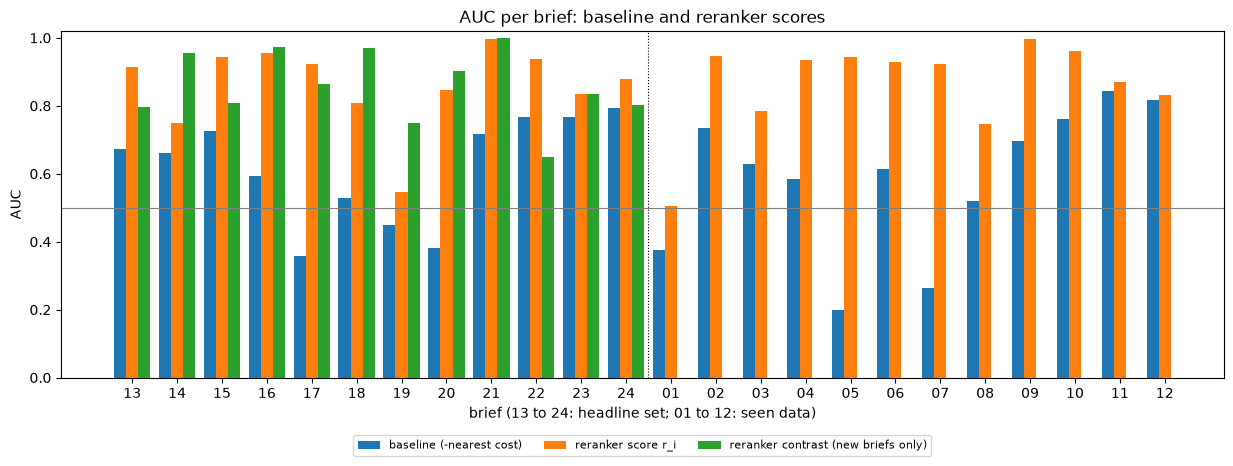

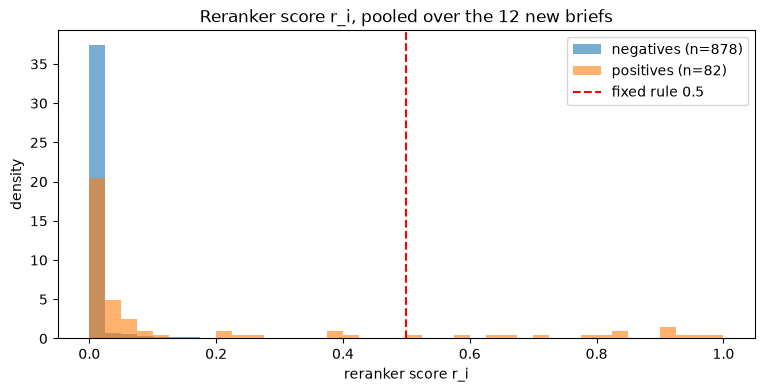

pooled r_i over new briefs: positives median 0.0221 (min 0.0000, max 0.9827), negatives median 0.0004 (min 0.0000, max 0.8865)

In [15]:
fig, ax = plt.subplots(figsize=(15, 4.5))
ids = NEW_IDS + SEEN_IDS
width = 0.27
for k, (name, label) in enumerate([("baseline", "baseline (-nearest cost)"), ("reranker", "reranker score r_i"), ("contrast", "reranker contrast (new briefs only)")]):
    ax.bar(np.arange(len(ids)) + k * width, [AUC[name].get(b, np.nan) for b in ids], width, label=label)
ax.set_xticks(np.arange(len(ids)) + width, [b[-2:] for b in ids])
ax.axvline(len(NEW_IDS) - 0.25, color="black", lw=0.8, ls=":")
ax.axhline(0.5, color="grey", lw=0.8)
ax.set_xlabel("brief (13 to 24: headline set; 01 to 12: seen data)"); ax.set_ylabel("AUC"); ax.set_ylim(0.0, 1.02)
ax.set_title("AUC per brief: baseline and reranker scores"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
plt.show()

pos_r = np.concatenate([S["reranker"][b][LAB[b]["pos"]] for b in NEW_IDS])
neg_r = np.concatenate([S["reranker"][b][LAB[b]["neg"]] for b in NEW_IDS])
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
ax.hist(neg_r, bins=bins, alpha=0.6, density=True, label=f"negatives (n={len(neg_r)})")
ax.hist(pos_r, bins=bins, alpha=0.6, density=True, label=f"positives (n={len(pos_r)})")
ax.axvline(RERANK_FIXED, color="red", ls="--", label="fixed rule 0.5")
ax.set_xlabel("reranker score r_i"); ax.set_ylabel("density"); ax.set_title("Reranker score r_i, pooled over the 12 new briefs"); ax.legend()
plt.show()
console.print(f"pooled r_i over new briefs: positives median {np.median(pos_r):.4f} (min {pos_r.min():.4f}, max {pos_r.max():.4f}), negatives median {np.median(neg_r):.4f} (min {neg_r.min():.4f}, max {neg_r.max():.4f})")

## Metrics JSON

Every measured number, the gate values, every bar clause as value and boolean, and the verdict by bar of each
hypothesis are written to `reports/E18-reranker-relevance-metrics.json`.

In [16]:
def per_query(qids):
    return {q: {n: AUC[n][q] for n in NAMES if q in AUC[n]} for q in qids}


metrics = {
    "batch": "E18", "notebook": "A",
    "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"docdistance": docdistance.__version__, "python": platform.python_version(), "numpy": np.__version__, "POT": ot.__version__,
                    "encoder_backend": dd.backend, "reranker_class": type(reranker).__name__, "reranker_defaults": "load_reranker()",
                    "reader": "default (auto by extension)", "DIFF_CHANGED_COST": DIFF_CHANGED_COST},
    "fixture_sha256": fixture_sha, "fixture_sha256_equals_registration": fixture_sha == REG["fixture_sha256"],
    "harness_check": {"passed": HARNESS_OK, "largest_abs_difference": HARNESS_MAX, "tolerance": HARNESS_TOL, "per_brief": harness},
    "statement_counts": {"report": N_REPORT, "briefs": {b: len(BRIEF_TEXTS[b]) for b in BRIEF_IDS}, "controls": {c: len(CONTROL_TEXTS[c]) for c in CONTROL_IDS}},
    "label_counts": {q: {"positives": int(l["pos"].sum()), "negatives": int(l["neg"].sum()), "hard_negatives": None if l["hard"] is None else int(l["hard"].sum())} for q, l in LAB.items()},
    "neutral_statements": int(IS_NEUTRAL.sum()),
    "auc_per_brief": per_query(BRIEF_IDS), "auc_hard_negatives_per_brief": AUC_HARD, "auc_per_control": per_query(CONTROL_IDS),
    "summary_new_briefs_headline": SUMMARY["new"], "summary_seen_briefs_no_bar": SUMMARY["seen"],
    "control_mean_auc": CONTROL_MEAN, "control_diff_to_baseline": CONTROL_DIFF,
    "section_reading": {n: {b: {"ranked_sections": SECTION[n][b][0], "top2_share": SECTION[n][b][1]} for b in BRIEF_IDS if b in SECTION[n]} for n in NAMES},
    "balanced_accuracy": {"fixed_cutoff_nearest_cost": FIXED, "otsu_reranker": OTSU, "fixed_rule_reranker_ge_0.5": FIXED_R,
                          "mean_new": {"fixed": FIXED_MEAN_NEW, "otsu": otsu_mean_new, "fixed_rule_0.5": fixed_r_mean_new},
                          "mean_seen_no_bar": {"fixed": mean_ba(FIXED, SEEN_IDS), "otsu": mean_ba(OTSU, SEEN_IDS), "fixed_rule_0.5": mean_ba(FIXED_R, SEEN_IDS)}},
    "gates": {"E18-H87": {"baseline_mean_auc_new": BASE_MEAN_NEW, "threshold": BATCH_GATE_AUC, "killed": H87_KILLED},
              "E18-H91": {"fixed_mean_ba_new": FIXED_MEAN_NEW, "threshold": H91_GATE_BA, "killed": H91_KILLED}},
    "clauses": {"E18-H87": {**H87_CLAUSES, "bar_met": H87_BAR_MET}, "E18-H91": {**H91_CLAUSES, "bar_met": H91_BAR_MET}},
    "verdict_by_bar": {"E18-H87": H87_VERDICT, "E18-H91": H91_VERDICT},
    "reranker_wall_seconds_per_grid": {"first_call": GRID_SECONDS[QUERY_IDS[0]], "briefs_02_to_24_median": float(np.median([GRID_SECONDS[q] for q in BRIEF_IDS[1:]])),
                                       "briefs_02_to_24_mean": float(np.mean([GRID_SECONDS[q] for q in BRIEF_IDS[1:]])), "per_query": GRID_SECONDS, "pairs_per_query": pairs},
    "grids_file": str(GRIDS_FILE.relative_to(ROOT)),
    "per_brief_table": PER_BRIEF,
    "wall_seconds": round(time.time() - T_START, 1),
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, default=float), encoding="utf-8")
console.print(f"written {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")
console.print(metrics["verdict_by_bar"])

written reports/E18-reranker-relevance-metrics.json (80333 bytes)

{'E18-H87': 'Confirmed', 'E18-H91': 'Refuted'}

## Conclusions

Verdicts are read on the registered bars only. Both gates passed: the baseline mean AUC over briefs 13 to 24 is 0.6183, far below 0.95, and the fixed cutoff 0.3253 on the nearest cost reads a mean balanced accuracy of 0.5080, below 0.65. The harness check passed: the copied cells reproduce the E17 baseline AUC of briefs 01 to 12 with a largest absolute difference of 0.0 (bar 1e-9). The fixture hash check passed for all 16 files. A separate scratch script that shares no function with the notebook (pairwise AUC count, brute-force Otsu split, its own cosine cost) gave the same mean AUC difference (0.242850) and the same Otsu mean balanced accuracy (0.640009) from the stored grids, with a difference of 0.0.

| hypothesis | headline reading on briefs 13 to 24 | bar | verdict by bar |
|---|---|---|---|
| E18-H87 reranker score | mean AUC 0.8611 against 0.6183, mean difference +0.2429, 12 of 12 briefs above 0, control mean AUC 0.8332 against 0.6780 (+0.1552) | +0.03, 10 of 12, control drop at most 0.01 | Confirmed |
| E18-H91 Otsu split of the reranker score | mean balanced accuracy 0.6400, 0.1320 above the fixed cutoff's 0.5080 | 0.70 and +0.10 | Refuted |

- **E18-H87** - all three clauses are met. The mean difference is +0.2429 (bootstrap interval [+0.1631, +0.3346], reported, no bar); the prediction of a gain of 0.15 or more is met; the smallest gains are on briefs 23 (+0.0697), 14 (+0.0866), 24 (+0.0867) and 19 (+0.0952), and no brief loses. Brief 19 stays weak in absolute terms (AUC 0.5455, hard-negative AUC 0.5859). The AUC against the negatives of the brief's own part is 0.8290 for the reranker against 0.6435 for the baseline, and the top-2 section share is 0.9167 against 0.4167, so the gain is not carried by the separation of the two parts. On briefs 01 to 12 (seen data, no bar) the mean difference is +0.2776 with 12 of 12 briefs above 0 and a reranker mean AUC of 0.8641 against 0.5865. The contrast of the reranker score (reported, no bar) reaches a mean AUC of 0.8588 on the new briefs, which is +0.2405 over the baseline but 0.0023 below the reranker score alone, and 0.8512 on the controls; on average the background changes little on top of the reranker, while per brief the AUC moves in both directions, from -0.2882 (brief 22) to +0.2078 (brief 14)
- **E18-H91** - the gate passed and the Otsu split does not reach 0.70. The mean balanced accuracy is 0.6400 (clause 1 not met, value 0.6400); the gain over the fixed cutoff is +0.1320 (clause 2 met). The split marks 2 to 7 statements per brief as a match with a true positive rate of 0.00 to 0.71 and a true negative rate of 0.95 to 1.00: the scores of a pair form a long tail, with a pooled median of 0.0221 for positives and 0.0004 for negatives, so the split takes the few highest statements and misses most positives. Brief 19 reads below 0.5 (0.4870, true positive rate 0). The fixed rule `r_i >= 0.5` reads 0.5817 (reported, no bar); on briefs 01 to 12 (seen) the Otsu split reads 0.5790
- **Wall time** - one `score_grid` per pair of documents takes a median of 13.5 s for a brief (372 to 930 sentence pairs, CPU, OpenVINO INT8) and a median of 35.6 s for a control (930 to 1209 pairs); the first call carried no visible warm-up cost (13.89 s)

**What the fixture cannot show** - the report is two articles on one broad topic, and the briefs are written by one author with the report in view. The labels are at section level, so a report statement outside the target sections that bears on the brief counts as a negative; the gain of the reranker may be understated by this and the balanced accuracy too. The reranker scores are not calibrated across pairs: the Otsu split of one pair reads its own long tail, and the cutoff differs per brief (0.0135 to 0.4834). With 12 briefs the sign test has little power, although 12 of 12 is the largest count possible. Briefs 13 to 24 were written after the E17 readings were known, which the registration states. The controls rest on one article and 7 summaries of it. The private pair of the user (a market research report against a client brief) is not in the repository and was not read. A confirmed lever on this fixture is a result for this fixture; whether it ships is a separate decision.
